# DAY4 실습 05 — 카이제곱 독립성 검정

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

한 행은 **운전 기록 1건**이다.

| 열 | 뜻 |
|---|---|
| `Type` | 제품 유형 (L : 저품질, M : 중품질, H : 고품질) |
| `Machine failure` | 고장 여부 (1 : 고장, 0 : 정상) |
| `Tool wear [min]` | 공구 사용시간 (분). 공구를 교체하면 0부터 다시 쌓인다 |
| `TWF` | 공구 마모 고장 여부 (Tool Wear Failure, 1 : 해당) |

**질문** : 제품 유형과 고장 여부는 관련이 있는가? 공구 사용시간과 고장 여부는 관련이 있는가?

**실습 전제** : 운전 기록끼리 서로 독립이라고 가정한다.

In [ ]:
# 데이터 확인 : 행·열 수, 제품 유형별 건수, 고장 건수
print("행·열:", data.shape)                               # shape : (행 수, 열 수)
print(data["Type"].value_counts())                       # value_counts : 값마다 몇 건인지 센다
print("고장 건수:", data["Machine failure"].sum(), "/ 공구 마모 고장 건수:", data["TWF"].sum())

행·열: (10000, 14)
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64
고장 건수: 339 / 공구 마모 고장 건수: 46


## 1. 독립성 검정

**독립성 검정**은 한 모집단에서 뽑은 자료를 두 범주형 변수로 분류해, 두 변수가 서로 관련이 있는지 검정한다.

**독립성 검정이 필요한 이유** : 교차표를 보면 제품 유형마다 고장률이 조금씩 다르다. 이 차이가 기록이 우연히 그렇게 나뉜 결과인지, 두 변수 사이에 관련이 있다고 볼 만한 차이인지는 눈으로 판단할 수 없다. 독립성 검정은 "두 변수가 관련이 없다면 이 정도 차이가 우연히 생길 수 있는가"를 p값으로 답한다. 두 변수 모두 범주형이므로 정규성 · 등분산 확인은 필요 없다.

**독립** : 한 변수의 범주가 바뀌어도 다른 변수의 비율이 달라지지 않는 상태다. 제품 유형과 고장 여부가 독립이라면, L · M · H 어느 유형이든 고장률이 전체 고장률(3.39%)과 같아야 한다.

**적용 사례**

| 분야 | 질문 |
|---|---|
| 설비 보전 | 제품 유형과 고장 여부가 관련이 있는가 |
| 공정 관리 | 작업 교대조와 불량 유형이 관련이 있는가 |
| 고객 관리 | 고객 등급과 문의 유형이 관련이 있는가 |

**가설 형식**

- 귀무가설(H₀): 두 변수는 독립이다. 한 변수의 범주에 따라 다른 변수의 비율이 달라지지 않는다. (P(A ∩ B) = P(A) × P(B))
- 대립가설(H₁): 두 변수는 독립이 아니다(관련이 있다). 한 변수의 범주에 따라 다른 변수의 비율이 달라진다. (P(A ∩ B) ≠ P(A) × P(B))

P(A ∩ B)는 A와 B가 함께 일어날 확률이다. 독립이면 이 확률이 각 확률의 곱과 같다.

| 구분 | 독립성 검정 |
|---|---|
| 묻는 질문 | 두 범주형 변수가 관련이 있는가 |
| 모집단과 범주형 변수 | 모집단 1개 · 범주형 변수 2개 (예 : 기록마다 제품 유형과 고장 여부를 확인) |
| 표본추출 방식 | 한 번에 추출한 뒤 두 변수로 분류 |
| 기대빈도 E | 행 합계 × 열 합계 ÷ 전체 |
| 함수 | `stats.chi2_contingency` |

**동질성 검정과의 차이** : 계산 · 함수 · p값은 같다. 집단마다 표본 크기를 미리 정해 뽑았으면 동질성, 한 번에 뽑은 뒤 두 변수로 나눴으면 독립성이다. 결론 문장도 "비율이 다르다"(동질성)와 "관련이 있다"(독립성)로 달라진다.

| 함수 | 기능 |
|---|---|
| `pd.crosstab(행으로 쓸 열, 열로 쓸 열)` | 교차표(관측빈도)를 만든다. 검정에는 이 건수표를 넣는다 |
| `pd.crosstab(..., normalize="index")` | 행마다 합이 1이 되는 비율표를 만든다. 차이의 크기를 읽을 때 쓰고, 검정에는 넣지 않는다 |
| `stats.contingency.expected_freq(교차표)` | 기대빈도. 독립이라면 칸마다 기대되는 건수 |
| `stats.chi2_contingency(교차표)` | 독립성 검정. `.statistic`(χ²) · `.pvalue`. contingency table은 교차표를 뜻한다 |

공식 문서 : [pandas.crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html) · [scipy.stats.contingency.expected_freq](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.expected_freq.html) · [scipy.stats.chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)

### 1-1. 제품 유형 × 고장 여부

1) 가설 설정
   - 귀무가설(H₀): 제품 유형과 고장 여부는 독립이다. 유형이 달라도 고장률은 같다. (P(유형 ∩ 고장) = P(유형) × P(고장))
   - 대립가설(H₁): 제품 유형과 고장 여부는 독립이 아니다. 유형에 따라 고장률이 다르다. (P(유형 ∩ 고장) ≠ P(유형) × P(고장))
2) 유의수준 : α = 0.05
3) 조건 확인 → 검정 : 교차표 · 비율표 · 그래프로 자료를 본 뒤, 기대빈도가 모두 5 이상인지 확인하고 `stats.chi2_contingency`
4) 결과 도출 : 관측빈도와 기대빈도를 비교해 어느 칸이 차이를 만들었는지 보고 두 줄 결론을 쓴다

Machine failure     0    1
Type                      
L                5765  235
M                2914   83
H                 982   21
Machine failure      0     1
Type                        
L                96.08  3.92
M                97.23  2.77
H                97.91  2.09


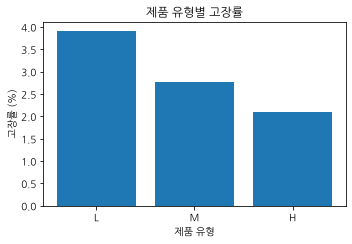

Machine failure       0      1
Type                          
L                5796.6  203.4
M                2895.4  101.6
H                 969.0   34.0
가장 작은 기대빈도: 34.0
χ²: 13.75 / p값: 0.001


In [ ]:
# [예제] AI4I 10,000건으로 제품 유형(L · M · H)과 고장 여부가 관련이 있는지 검정한다
# 귀무가설(H₀): 제품 유형과 고장 여부는 독립이다. 유형이 달라도 고장률은 같다. (P(유형 ∩ 고장) = P(유형) × P(고장))
# 대립가설(H₁): 제품 유형과 고장 여부는 독립이 아니다. 유형에 따라 고장률이 다르다. (P(유형 ∩ 고장) ≠ P(유형) × P(고장))
# 유의수준 α = 0.05

# 1) 교차표(관측빈도) : 제품 유형 × 고장 여부 (3행 × 2열)
type_table = pd.crosstab(data["Type"], data["Machine failure"]).loc[["L", "M", "H"]]   # 행 순서를 L · M · H 로 맞춘다
print(type_table)

# 2) 비율표 : 행마다 합이 100% 가 되도록 바꾼다
type_ratio = pd.crosstab(data["Type"], data["Machine failure"], normalize="index").loc[["L", "M", "H"]] * 100
#   normalize="index" : 행(유형)마다 건수를 행 합계로 나눈다. 100 을 곱해 % 로 바꾼다
print(type_ratio.round(2))

# 3) 그래프 : 유형별 고장률(열 1)을 막대로 본다
plt.figure(figsize=(5, 3.5))
plt.bar(type_ratio.index, type_ratio[1])                   # type_ratio[1] : 열 이름 1(고장) 열 = 유형별 고장률(%)
plt.title("제품 유형별 고장률")
plt.xlabel("제품 유형")
plt.ylabel("고장률 (%)")
plt.tight_layout()
plt.show()

# 4) 조건 확인 : 기대빈도 (독립이라면 칸마다 기대되는 건수)
type_expected = stats.contingency.expected_freq(type_table)
print(pd.DataFrame(type_expected, index=type_table.index, columns=type_table.columns).round(1))
print("가장 작은 기대빈도:", round(type_expected.min(), 1))

# 5) 독립성 검정
type_result = stats.chi2_contingency(type_table)            # 검정에는 비율표가 아니라 건수 교차표를 넣는다
print("χ²:", round(type_result.statistic, 2), "/ p값:", round(type_result.pvalue, 4))

# [결과]
# - 고장률 L 3.92% · M 2.77% · H 2.09%, 가장 작은 기대빈도 34.0 ≥ 5 → 조건을 만족한다
# - 고장 칸 관측 vs 기대 : L 235 > 203.4, M 83 < 101.6, H 21 < 34.0 → L 은 기대보다 고장이 많고 M · H 는 적다
# - χ² = 13.75, p = 0.001
# - 통계적 결론 : p = 0.001 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 제품 유형과 고장 여부는 독립이라고 보기 어렵다. 고장률은 L 3.92%로 가장 높고 H 2.09%로 가장 낮다 (10,000건)

## 2. 실습 : 공구 사용시간 구간과 고장 여부

공구 사용시간은 수치형 변수라 그대로는 독립성 검정에 쓸 수 없다. 구간으로 나눠 범주형 변수로 바꾼 뒤, 고장 여부와 관련이 있는지 검정한다.

| 함수 | 기능 |
|---|---|
| `pd.cut(열, bins=, labels=, include_lowest=True)` | 수치를 구간으로 나눠 범주로 바꾼다. `include_lowest=True`는 첫 경계값(0)도 첫 구간에 넣는다 |

**bins 읽는 법** : `bins=[0, 100, 200, 260]`은 경계값 4개로 구간 3개를 만든다. 각 구간은 오른쪽 경계값을 포함한다.

| 구간 | 범위 | labels |
|---|---|---|
| 1 | 0분 이상 ~ 100분 이하 | 0~100분 |
| 2 | 100분 초과 ~ 200분 이하 | 100~200분 |
| 3 | 200분 초과 ~ 260분 이하 | 200분 초과 |

260은 공구 사용시간의 최댓값(253분)보다 크게 잡은 끝값이다. `labels`는 구간마다 붙일 이름이라 구간 수와 개수가 같아야 한다.

공식 문서 : [pandas.cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html)

In [ ]:
# [예제] 공구 사용시간을 0 ~ 100분, 100 ~ 200분, 200분 초과 세 구간으로 나눈다
data["wear_group"] = pd.cut(data["Tool wear [min]"], bins=[0, 100, 200, 260],
                            labels=["0~100분", "100~200분", "200분 초과"], include_lowest=True)
#   bins : 경계값 4개 → 구간 3개. labels : 구간마다 붙일 이름 3개
#   include_lowest=True : 사용시간 0분(공구를 막 교체한 기록)도 첫 구간에 넣는다. 빼면 0분 기록이 빈 값이 된다
print(data["wear_group"].value_counts().sort_index())   # sort_index : 건수 순서가 아니라 구간 순서대로 정렬

# [결과]
# - 0~100분 4,667건 · 100~200분 4,571건 · 200분 초과 762건

wear_group
0~100분      4667
100~200분    4571
200분 초과      762
Name: count, dtype: int64


In [ ]:
# [실습]
# 상황 : 공구 사용시간 구간과 고장 여부가 관련이 있는지 검정한다.
#        귀무가설(H₀): 공구 사용시간 구간과 고장 여부는 독립이다. 구간이 달라도 고장률은 같다. (P(구간 ∩ 고장) = P(구간) × P(고장))
#        대립가설(H₁): 공구 사용시간 구간과 고장 여부는 독립이 아니다. 구간에 따라 고장률이 다르다. (P(구간 ∩ 고장) ≠ P(구간) × P(고장))
#        유의수준 α = 0.05
# wear_group 과 Machine failure 로 교차표와 비율표를 만들고, 가장 작은 기대빈도를 확인한 뒤 카이제곱 검정의 χ² · p값을 구하시오.



## 3. 기대빈도가 작을 때 : 범주 합치기

기대빈도가 5 미만인 칸이 있으면 χ²로 구한 p값이 부정확해진다. 이때는 범주를 합쳐 기대빈도를 키우거나 표본을 더 모은다. 합쳐서 2×2 표가 되면 Fisher 정확검정으로도 확인할 수 있다.

**범주를 합치는 기준**

| 기준 | 내용 | 예 |
|---|---|---|
| 순서가 있는 범주 | 이웃한 구간끼리 합친다 | 공구 사용시간 0~50분 + 50~100분 |
| 순서가 없는 범주 | 성격이 비슷해 이름 하나로 부를 수 있는 것끼리 합친다 | M(중품질) + H(고품질) → M·H |
| 정하는 때 | 검정 전에 기대빈도만 보고 정한다. p값을 보고 합치는 방법을 바꾸지 않는다 | |
| 합친 뒤 | 기대빈도를 다시 확인한다. 2×2 표인데 5 미만 칸이 남으면 Fisher 정확검정을 쓴다 | |
| 결론 쓸 때 | 무엇을 합쳤는지 적는다. 합친 범주 안의 차이는 말할 수 없다 | M과 H의 차이는 알 수 없다 |

| 함수 | 기능 |
|---|---|
| `np.where(조건, 참일 때 값, 거짓일 때 값)` | 행마다 조건을 보고 두 값 중 하나를 넣는다. 범주를 새로 묶을 때 쓴다 |
| `stats.fisher_exact(2×2 교차표)` | 2×2 표의 정확 검정 |

공식 문서 : [scipy.stats.chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) · [numpy.where](https://numpy.org/doc/stable/reference/generated/numpy.where.html) · [scipy.stats.fisher_exact](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html)

In [ ]:
# [예제] 저등급(L) 제품과 나머지(M·H) 제품의 공구 마모 고장(TWF) 비율을 비교한다.
# 공구 마모 고장은 전체 46건뿐이라 일부 기대빈도가 작을 수 있다.
# 업무 목적 : L 제품과 M·H 제품의 고장률을 비교하기 위해 M과 H를 하나의 그룹으로 묶는다.

# 귀무가설(H₀): L 제품과 M·H 제품의 모집단 공구 마모 고장률은 같다. (p_L = p_MH)
# 대립가설(H₁): L 제품과 M·H 제품의 모집단 공구 마모 고장률은 다르다. (p_L ≠ p_MH)


# 1) 합치기 전 : 교차표와 기대빈도 확인
twf_table = pd.crosstab(data["Type"], data["TWF"]).loc[["L", "M", "H"]]
print(twf_table)

twf_expected = stats.contingency.expected_freq(twf_table)

print(
    pd.DataFrame(
        twf_expected,
        index=twf_table.index,
        columns=twf_table.columns
    ).round(1)
)   # 합치기 전 H 행의 TWF 기대빈도가 5 미만인지 확인


# 2) 업무 목적에 따른 범주 합치기 : M과 H를 'M·H'로 합친다.
# L 제품과 나머지 제품의 고장률을 비교하기 위한 그룹 구성이다.
# 주의 : 기대빈도가 작다는 이유만으로 합치는 것이 아니라, 업무적으로 합칠 근거가 있어야 한다.

data["type_group"] = np.where(data["Type"] == "L", "L", "M·H")
# Type이 L이면 "L", 아니면(M 또는 H) "M·H"를 넣은 새 열을 만든다.

twf_table2 = pd.crosstab(data["type_group"], data["TWF"])
print(twf_table2)

twf_expected2 = stats.contingency.expected_freq(twf_table2)

print("합친 뒤 가장 작은 기대빈도:", round(twf_expected2.min(), 1))
# 기대빈도가 충분한지 확인한다.


# 3) 검정 : L과 M·H의 공구 마모 고장률 비교
# 귀무가설(H₀): L 제품과 M·H 제품의 모집단 공구 마모 고장률은 같다.
# 대립가설(H₁): L 제품과 M·H 제품의 모집단 공구 마모 고장률은 다르다.

# 카이제곱 검정, 그리고 2×2 표이므로 Fisher 정확검정으로도 확인한다.
twf_result = stats.chi2_contingency(twf_table2)

print("χ²:", round(twf_result.statistic, 2),
      "/ p값:", round(twf_result.pvalue, 4))

print("Fisher 정확검정 p값:",
      round(stats.fisher_exact(twf_table2).pvalue, 4))


# [결과]
# - 합치기 전 H 행의 TWF 기대빈도는 4.6 < 5
#
# - 업무 목적에 따라 M과 H를 합치면 가장 작은 기대빈도는 18.4 ≥ 5이다.
# - 카이제곱 검정 p = 0.5264, Fisher 정확검정 p = 0.4531
#
# - 통계적 결론 : p = 0.5264 ≥ 0.05이므로 귀무가설을 기각하지 못한다.
#
# - 사실적 결론 : 저등급(L) 제품과 나머지(M·H) 제품의
#   공구 마모 고장률이 다르다고 볼 통계적 근거가 부족하다.
#

TWF      0   1
Type          
L     5975  25
M     2983  14
H      996   7
TWF        0     1
Type              
L     5972.4  27.6
M     2983.2  13.8
H      998.4   4.6
TWF            0   1
type_group          
L           5975  25
M·H         3979  21
합친 뒤 가장 작은 기대빈도: 18.4
χ²: 0.4 / p값: 0.5264
Fisher 정확검정 p값: 0.4531


## 4. 정리 : 독립성 검정

**결과를 읽는 순서** : 교차표(건수) · 비율표 · 그래프 → 기대빈도(모두 5 이상인가) → χ² · p값 → 관측 vs 기대로 어긋난 칸 → 두 줄 결론

| 항목 | 내용 |
|---|---|
| 질문 | 두 범주형 변수가 관련이 있는가 |
| 자료를 모은 방식 | 한 번에 뽑은 뒤 기록마다 두 변수로 분류 |
| 함수 | `stats.chi2_contingency(교차표)` |
| 기대빈도 | 행 합계 × 열 합계 ÷ 전체 (두 변수가 독립이라면 나올 건수) |
| 조건 | 관측 독립, 관측 하나는 한 칸에만 한 번 센다, 기대빈도 모두 5 이상. 작으면 의미가 맞는 범주를 합친다 |

### 해석 시 유의점

| 항목 | 해석 기준 |
|---|---|
| 입력 | 	검정에는 실제 건수로 만든 교차표를 사용한다. 비율표를 넣으면 표본 크기 정보가 사라져 올바른 p값을 얻을 수 없다. |
| 차이의 크기 | 	표본이 크면 작은 차이도 통계적으로 유의할 수 있다. 실제 차이가 얼마나 큰지는 집단별 비율(%)을 함께 비교한다.|
| 기각했을 때 | 두 범주형 변수 사이에 관련성이 있다는 통계적 근거가 있다. 관측빈도와 기대빈도를 비교하면 어느 칸에서 예상보다 많이 또는 적게 발생했는지 살펴볼 수 있다.
| 기대빈도 | 기대빈도가 너무 작으면 카이제곱 검정의 p값이 부정확할 수 있다. 2×2 교차표에서는 피셔 정확검정을 고려할 수 있다.|
공식 문서 : [scipy.stats.chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) · [pandas.crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html) · [scipy.stats.fisher_exact](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html)